In [4]:
from pathlib import Path
import json
import sys

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import IQRClipper

print("Project folder:", project_root)

Project folder: /workspace


In [6]:
csv_path = project_root / "data/raw/student_mental_health.csv"
if not csv_path.exists():
    csv_path = project_root / "student_mental_health.csv"

if not csv_path.exists():
    raise FileNotFoundError("Put student_mental_health.csv in data/raw/")

df = pd.read_csv(csv_path)
df = df.dropna(subset=["Mental_Health_Risk"]).copy()

X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

print("Dataset:", df.shape)
print("Input features:", X.shape[1])

Dataset: (2000, 17)
Input features: 15


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

class_mapping = {"Low": 0, "Medium": 1, "High": 2}
label_names = ["Low", "Medium", "High"]

y_train = y_train.map(class_mapping)
y_test = y_test.map(class_mapping)

print("Training students:", len(X_train))
print("Test students:", len(X_test))
print("Training labels:", y_train.value_counts().sort_index())

Training students: 1600
Test students: 400
Training labels: Mental_Health_Risk
0    528
1    528
2    544
Name: count, dtype: int64


In [8]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("iqr", IQRClipper()),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

print("Numeric columns:", len(numeric_columns))
print("Categorical columns:", len(categorical_columns))

Numeric columns: 10
Categorical columns: 5


In [9]:
models = {
    "SVM": SVC(kernel="rbf"),
    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=2
    )
}

parameter_grids = {
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.1, 0.01]
    },
    "XGBoost": {
        "model__max_depth": [2, 3, 4],
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1]
    }
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print("Models to optimize:", list(models))

Models to optimize: ['SVM', 'XGBoost']


In [10]:
searches = {}
results = []

for name, model in models.items():
    print("Tuning:", name)

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(model))
    ])

    search = GridSearchCV(
        pipeline,
        parameter_grids[name],
        cv=cv,
        scoring="f1_macro",
        n_jobs=1,
        error_score="raise"
    )
    search.fit(X_train, y_train)

    searches[name] = search
    results.append({
        "Model": name,
        "CV F1 Macro": search.best_score_,
        "Best Parameters": str(search.best_params_)
    })

comparison = pd.DataFrame(results).sort_values(
    "CV F1 Macro", ascending=False
).reset_index(drop=True)

display(comparison.round(3))

Tuning: SVM
Tuning: XGBoost


,Model,CV F1 Macro,Best Parameters
0,SVM,0.738,"{'model__C': 10, 'model__gamma': 0.01}"
1,XGBoost,0.705,"{'model__learning_rate': 0.1, 'model__max_dept..."


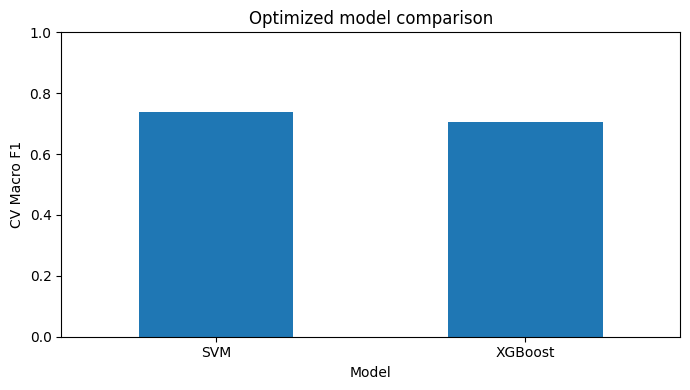

Selected model: SVM
Best settings: {'model__C': 10, 'model__gamma': 0.01}


In [11]:
comparison.plot(
    x="Model", y="CV F1 Macro", kind="bar",
    figsize=(7, 4), legend=False
)
plt.ylim(0, 1)
plt.ylabel("CV Macro F1")
plt.title("Optimized model comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

best_model_name = comparison.loc[0, "Model"]
best_pipeline = searches[best_model_name].best_estimator_

print("Selected model:", best_model_name)
print("Best settings:", searches[best_model_name].best_params_)